In [1]:
from __future__ import annotations
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
def print_matrix(M):
    print(pd.DataFrame(D2).to_string(index=False, header=False, float_format=lambda x: f"{x:.4f}"))

In [3]:
def squared_l2_distance_from_gram(gram: np.ndarray) -> np.ndarray:
    diagonal = np.diag(gram)
    return np.maximum(diagonal[:, None] + diagonal[None, :] - 2.0 * gram, 0.0)

In [4]:
def exact_gaussian_kde_l2_gram(
        samples: np.ndarray,
        h_grid: np.ndarray,
) -> np.ndarray:
    samples = np.asarray(samples, dtype=float)
    h_grid = np.asarray(h_grid, dtype=float)
    n = len(samples)
    squared_differences = (samples[:, None] - samples[None, :]) ** 2
    gram = np.empty((len(h_grid), len(h_grid)), dtype=float)
    N = len(h_grid)
    for i in range(N):
        for j in range(i, N):
            h_i = h_grid[i]
            h_j = h_grid[j]
            variance = h_i**2 + h_j**2
            value = np.exp(-squared_differences / (2.0 * variance)).sum()
            value /= n**2 * np.sqrt(2.0 * np.pi * variance)
            gram[i, j] = value
            gram[j, i] = value
    return gram

In [5]:
def beta2_divergence_matrix(
        samples: np.ndarray,
        h_grid: np.ndarray,
) -> np.ndarray:
    gram = exact_gaussian_kde_l2_gram(samples=samples, h_grid=h_grid)
    return 0.5 * squared_l2_distance_from_gram(gram=gram)

In [6]:
def beta2_similarity_matrix(
        samples: np.ndarray,
        h_grid: np.ndarray,
        tau: float = 1.0,
) -> np.ndarray:
    if tau <= 0.0:
        raise ValueError("tau must be positive.")
    divergence = beta2_divergence_matrix(samples=samples, h_grid=h_grid)
    similarity = np.exp(-float(tau) * divergence)
    np.fill_diagonal(a=similarity, val=1.0)
    return similarity

In [27]:
rng = np.random.default_rng(12345)
n = 200
N = 60
tau = 1.0
samples = rng.normal(loc=0.0, scale=1.0, size=n)
h_grid = np.geomspace(start=0.1, stop=1.0, num=N)
# print(h_grid)
D2 = beta2_divergence_matrix(samples=samples, h_grid=h_grid)
SimMatr = beta2_similarity_matrix(samples=samples, h_grid=h_grid, tau=tau)
# print()
# print_matrix(D2)
# print()
# print_matrix(SimMatr)

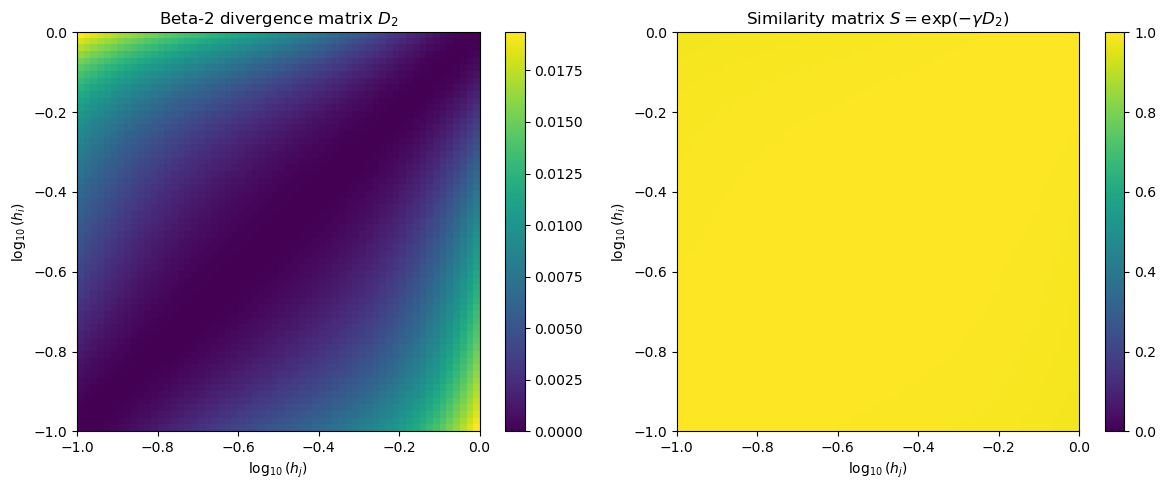

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

extent = [
    np.log10(h_grid[0]),
    np.log10(h_grid[-1]),
    np.log10(h_grid[0]),
    np.log10(h_grid[-1]),
]

image_d2 = axes[0].imshow(
    D2,
    origin="lower",
    aspect="auto",
    extent=extent,
    cmap="viridis",
)
axes[0].set_title(r"Beta-2 divergence matrix $D_2$")
axes[0].set_xlabel(r"$\log_{10}(h_j)$")
axes[0].set_ylabel(r"$\log_{10}(h_i)$")
fig.colorbar(image_d2, ax=axes[0])

image_similarity = axes[1].imshow(
    SimMatr,
    origin="lower",
    aspect="auto",
    extent=extent,
    cmap="viridis",
    vmin=0.0,
    vmax=1.0,
)
axes[1].set_title(r"Similarity matrix $S=\exp(-\gamma D_2)$")
axes[1].set_xlabel(r"$\log_{10}(h_j)$")
axes[1].set_ylabel(r"$\log_{10}(h_i)$")
fig.colorbar(image_similarity, ax=axes[1])

plt.tight_layout()
plt.show()

In [8]:
def perron_vector(matrix: np.ndarray) -> np.ndarray:
    matrix = np.asarray(matrix, dtype=float)
    if matrix.ndim != 2 or matrix.shape[0] != matrix.shape[1]:
        raise ValueError("The matrix must be square.")
    if not np.allclose(matrix, matrix.T, atol=1e-12):
        raise ValueError("The matrix must be symmetric.")
    if np.any(matrix < 0):
        raise ValueError("The matrix must be nonnegative.")

    eigenvalues, eigenvectors = np.linalg.eigh(matrix)
    vector = eigenvectors[:, int(np.argmax(eigenvalues))]
    if np.sum(vector) < 0:
        vector = -vector
    return vector / np.sum(vector)

In [9]:
vec = perron_vector(matrix=SimMatr)
print(vec)

[0.01662285 0.01662856 0.01663396 0.01663905 0.01664383 0.01664829
 0.01665243 0.01665627 0.01665981 0.01666306 0.01666603 0.01666876
 0.01667124 0.0166735  0.01667556 0.01667744 0.01667916 0.01668072
 0.01668215 0.01668345 0.01668463 0.0166857  0.01668667 0.01668754
 0.01668832 0.016689   0.01668959 0.01669009 0.01669051 0.01669083
 0.01669107 0.01669122 0.01669128 0.01669124 0.01669111 0.01669086
 0.0166905  0.01669    0.01668936 0.01668854 0.01668754 0.01668631
 0.01668483 0.01668307 0.01668098 0.01667853 0.01667566 0.01667233
 0.01666847 0.01666404 0.01665897 0.0166532  0.01664667 0.0166393
 0.01663103 0.01662179 0.01661151 0.01660013 0.0165876  0.01657384]


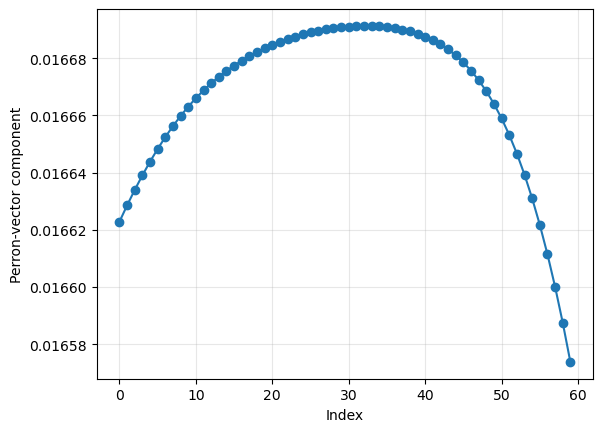

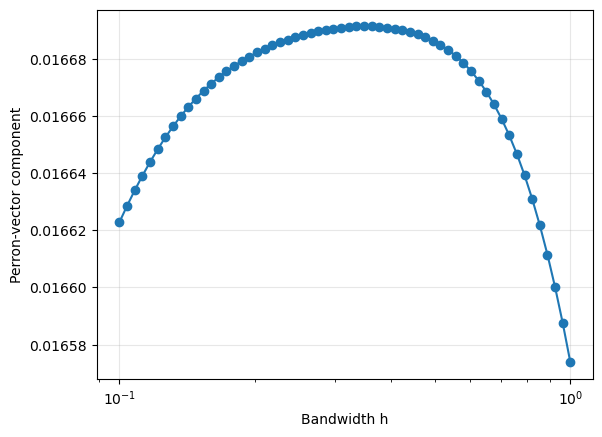

In [10]:
plt.plot(vec, marker="o")
plt.xlabel("Index")
plt.ylabel("Perron-vector component")
plt.grid(alpha=0.3)
plt.show()

plt.plot(h_grid, vec, marker="o")
plt.xscale("log")  # appropriate for a geometric bandwidth grid
plt.xlabel("Bandwidth h")
plt.ylabel("Perron-vector component")
plt.grid(alpha=0.3)
plt.show()

In [11]:
def spectral_choice_from_similarity(
        similarity_matrix: np.ndarray,
) -> dict[str, np.ndarray | int | float]:
    vector = perron_vector(matrix=similarity_matrix)
    return {
        "selected_index": int(np.argmax(vector)),
        "perron_vector": vector,
        "selected_weight": float(np.max(vector)),
    }

Plot the ISE($h$)-curve

In [13]:
def exact_oracle_ise_values(
        samples: np.ndarray,
        h_grid: np.ndarray,
        sigma2: float = 1.0,
) -> np.ndarray:
    samples = np.asarray(samples, dtype=float)
    h_grid = np.asarray(h_grid, dtype=float)
    sigma = float(np.sqrt(sigma2))
    n = len(samples)
    squared_differences = (samples[:, None] - samples[None, :]) ** 2
    kde_squared_integrals = []
    cross_integrals = []
    for h in h_grid:
        variance = 2.0 * h**2
        kde_squared = np.exp(-squared_differences / (2.0 * variance)).sum()
        kde_squared /= n**2 * np.sqrt(2.0 * np.pi * variance)
        kde_squared_integrals.append(kde_squared)

        variance = sigma2 + h**2
        cross = np.exp(-samples**2 / (2.0 * variance)).sum()
        cross /= n * np.sqrt(2.0 * np.pi * variance)
        cross_integrals.append(cross)
    true_squared_integral = 1.0 / (2.0 * np.sqrt(np.pi) * sigma)
    return (
        np.asarray(kde_squared_integrals)
        - 2.0 * np.asarray(cross_integrals)
        + true_squared_integral
    )

In [14]:
ise_values = exact_oracle_ise_values(samples, h_grid)

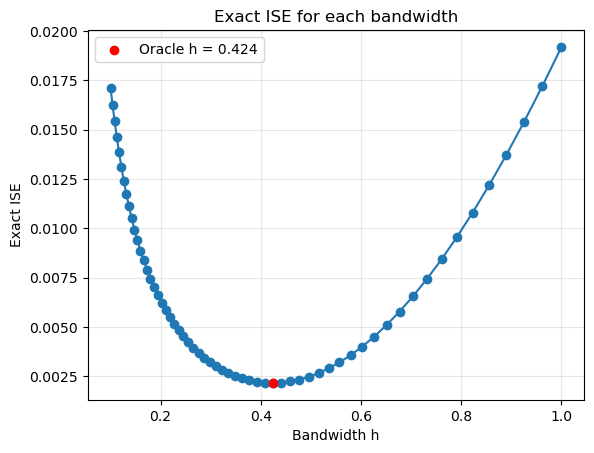

In [15]:
oracle_index = np.argmin(ise_values)

plt.plot(h_grid, ise_values, marker="o")
plt.scatter(
    h_grid[oracle_index],
    ise_values[oracle_index],
    color="red",
    label=f"Oracle h = {h_grid[oracle_index]:.3f}",
    zorder=3,
)
plt.xlabel("Bandwidth h")
plt.ylabel("Exact ISE")
plt.title("Exact ISE for each bandwidth")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [16]:
choice = spectral_choice_from_similarity(SimMatr)

spectral_index = choice["selected_index"]
spectral_h = h_grid[spectral_index]

ise_values = exact_oracle_ise_values(
    samples=samples,
    h_grid=h_grid,
    sigma2=1.0,
)

oracle_index = int(np.argmin(ise_values))
oracle_h = h_grid[oracle_index]

print(f"Spectral bandwidth: h = {spectral_h:.6f}")
print(f"Oracle bandwidth:   h = {oracle_h:.6f}")
print(f"Spectral ISE:       {ise_values[spectral_index]:.6f}")
print(f"Minimum ISE:        {ise_values[oracle_index]:.6f}")

Spectral bandwidth: h = 0.348637
Oracle bandwidth:   h = 0.423759
Spectral ISE:       0.002511
Minimum ISE:        0.002160


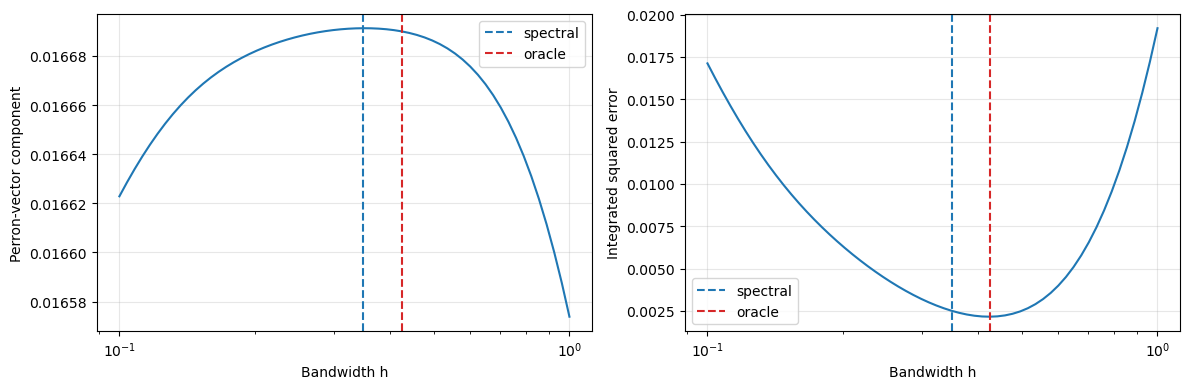

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(h_grid, choice["perron_vector"])
axes[0].axvline(
    spectral_h,
    color="tab:blue",
    linestyle="--",
    label="spectral",
)
axes[0].axvline(
    oracle_h,
    color="tab:red",
    linestyle="--",
    label="oracle",
)
axes[0].set_xscale("log")
axes[0].set_xlabel("Bandwidth h")
axes[0].set_ylabel("Perron-vector component")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(h_grid, ise_values)
axes[1].axvline(
    spectral_h,
    color="tab:blue",
    linestyle="--",
    label="spectral",
)
axes[1].axvline(
    oracle_h,
    color="tab:red",
    linestyle="--",
    label="oracle",
)
axes[1].set_xscale("log")
axes[1].set_xlabel("Bandwidth h")
axes[1].set_ylabel("Integrated squared error")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [18]:
def exact_gaussian_mise_values(
    h_grid: np.ndarray,
    n: int,
    sigma2: float = 1.0,
) -> np.ndarray:
    h_grid = np.asarray(h_grid, dtype=float)
    sigma = np.sqrt(sigma2)

    integrated_kernel_square = 1.0 / (2.0 * np.sqrt(np.pi))

    integrated_smoothed_square = (
        1.0
        / (
            2.0
            * np.sqrt(np.pi)
            * np.sqrt(sigma2 + h_grid**2)
        )
    )

    smoothed_truth_overlap = (
        1.0
        / np.sqrt(
            2.0 * np.pi * (2.0 * sigma2 + h_grid**2)
        )
    )

    integrated_truth_square = (
        1.0 / (2.0 * np.sqrt(np.pi) * sigma)
    )

    return (
        integrated_kernel_square / (n * h_grid)
        + (1.0 - 1.0 / n) * integrated_smoothed_square
        - 2.0 * smoothed_truth_overlap
        + integrated_truth_square
    )

In [19]:
ise_values = exact_oracle_ise_values(
    samples=samples,
    h_grid=h_grid,
    sigma2=1.0,
)

mise_values = exact_gaussian_mise_values(
    h_grid=h_grid,
    n=len(samples),
    sigma2=1.0,
)

ise_index = int(np.argmin(ise_values))
mise_index = int(np.argmin(mise_values))

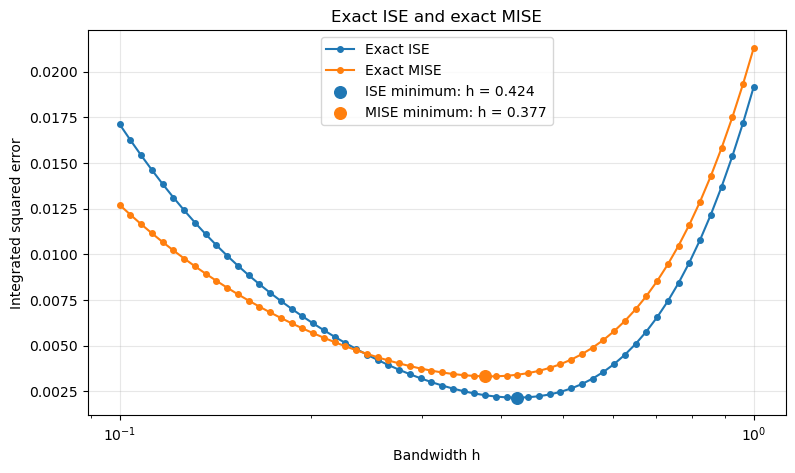

In [20]:
plt.figure(figsize=(9, 5))

plt.plot(
    h_grid,
    ise_values,
    marker="o",
    markersize=4,
    label="Exact ISE",
)

plt.plot(
    h_grid,
    mise_values,
    marker="o",
    markersize=4,
    label="Exact MISE",
)

plt.scatter(
    h_grid[ise_index],
    ise_values[ise_index],
    color="tab:blue",
    s=70,
    zorder=3,
    label=f"ISE minimum: h = {h_grid[ise_index]:.3f}",
)

plt.scatter(
    h_grid[mise_index],
    mise_values[mise_index],
    color="tab:orange",
    s=70,
    zorder=3,
    label=f"MISE minimum: h = {h_grid[mise_index]:.3f}",
)

plt.xscale("log")
plt.xlabel("Bandwidth h")
plt.ylabel("Integrated squared error")
plt.title("Exact ISE and exact MISE")
plt.grid(alpha=0.3)
plt.legend()
plt.show()